# LiverCare AI – Liver Disease Classification Using Logistic Regression

## Project Overview
LiverCare AI is a machine learning project that uses Logistic Regression to classify whether a person is likely to belong to the liver disease patient group or the non-liver disease patient group based on medical attributes.
The project focuses on understanding binary classification, probability-based prediction, sigmoid function, decision thresholds, feature scaling, class weights, and model evaluation.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    log_loss,
    confusion_matrix,
    classification_report
)


## Data Understanding and Exploration

In [30]:
df = pd.read_csv(r"C:\Users\dell\Desktop\mitali\indian_liver_patient.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [31]:
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Column Names:
Index(['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin',
       'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
       'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin',
       'Albumin_and_Globulin_Ratio', 'Dataset'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                  

In [ ]:
df["Gender"] = df["Gender"].map({
    "Male": 1,
    "Female": 0
})


df["Dataset"] = df["Dataset"].map({
    1: 1,
    2: 0
})

X = df.drop("Dataset", axis=1)
y = df["Dataset"]

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65       0              0.7               0.1                   187   
1   62       1             10.9               5.5                   699   
2   62       1              7.3               4.1                   490   
3   58       1              1.0               0.4                   182   
4   72       1              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Protiens  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Ratio  
0      3.3                        0.90  



## Splitting the Dataset

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (466, 10)
Testing data: (117, 10)


In [34]:

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Preprocessing will be handled by the Pipeline.")


Training data: (466, 10)
Testing data: (117, 10)
Preprocessing will be handled by the Pipeline.


In [ ]:
##  Understanding the Sigmoid Function

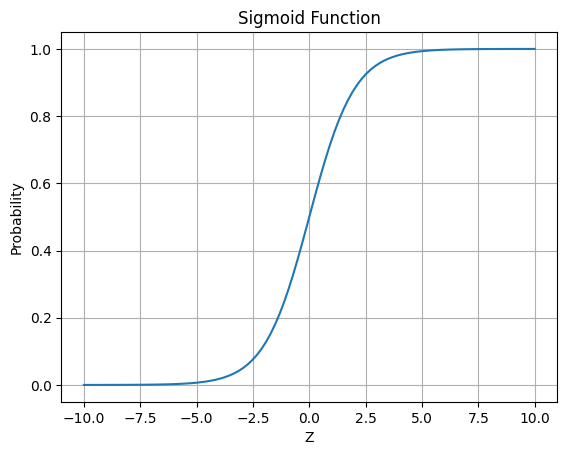

In [35]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-10, 10, 100)

probability = sigmoid(z)

plt.plot(z, probability)
plt.xlabel("Z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.grid()
plt.show()

In [ ]:
##  Building the Logistic Regression Model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


model = Pipeline([

    
    ("imputer", SimpleImputer(strategy="median")),

    
    ("scaler", StandardScaler()),

    # Logistic Regression
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        C=1.0
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:

y_probability = model.predict_proba(X_test)[:, 1]


threshold = 0.5

y_pred = (y_probability >= threshold).astype(int)

print("Predictions completed!")

Predictions completed!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nLog Loss:", log_loss(y_test, y_probability))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Liver", "Liver"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

Accuracy: 0.7350427350427351

Log Loss: 0.45300862783102486

Classification Report:
              precision    recall  f1-score   support

   Non-Liver       0.67      0.18      0.28        34
       Liver       0.74      0.96      0.84        83

    accuracy                           0.74       117
   macro avg       0.70      0.57      0.56       117
weighted avg       0.72      0.74      0.68       117


Confusion Matrix:
[[ 6 28]
 [ 3 80]]


In [ ]:
balanced_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0
    ))
])

balanced_model.fit(X_train, y_train)


balanced_probability = balanced_model.predict_proba(X_test)[:, 1]

balanced_pred = (balanced_probability >= 0.5).astype(int)


print("BALANCED LOGISTIC REGRESSION")

print("\nAccuracy:")
print(accuracy_score(y_test, balanced_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    balanced_pred,
    target_names=["Non-Liver", "Liver"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, balanced_pred, labels=[0, 1]))

BALANCED LOGISTIC REGRESSION

Accuracy:
0.7350427350427351

Classification Report:
              precision    recall  f1-score   support

   Non-Liver       0.53      0.85      0.65        34
       Liver       0.92      0.69      0.79        83

    accuracy                           0.74       117
   macro avg       0.72      0.77      0.72       117
weighted avg       0.81      0.74      0.75       117


Confusion Matrix:
[[29  5]
 [26 57]]


In [40]:
from sklearn.metrics import confusion_matrix, accuracy_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    predictions = (
        balanced_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    print("\nThreshold:", threshold)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("True Negative:", tn)
    print("False Positive:", fp)
    print("False Negative:", fn)
    print("True Positive:", tp)


Threshold: 0.3
Accuracy: 0.744
True Negative: 9
False Positive: 25
False Negative: 5
True Positive: 78

Threshold: 0.4
Accuracy: 0.761
True Negative: 21
False Positive: 13
False Negative: 15
True Positive: 68

Threshold: 0.5
Accuracy: 0.735
True Negative: 29
False Positive: 5
False Negative: 26
True Positive: 57

Threshold: 0.6
Accuracy: 0.667
True Negative: 33
False Positive: 1
False Negative: 38
True Positive: 45

Threshold: 0.7
Accuracy: 0.615
True Negative: 34
False Positive: 0
False Negative: 45
True Positive: 38



## Confusion Matrix

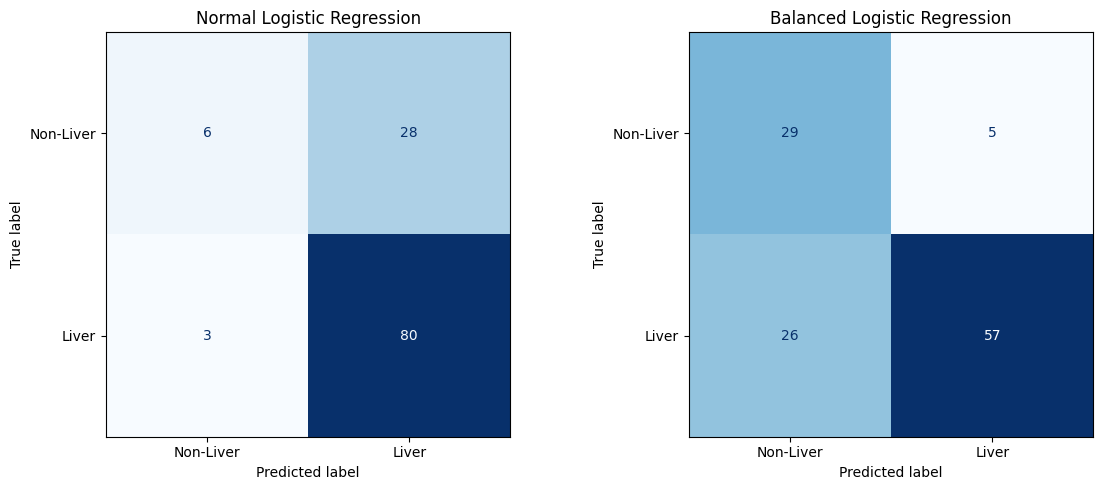

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm_normal = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
)

cm_balanced = confusion_matrix(
    y_test, balanced_pred, labels=[0, 1]
)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))


disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_normal,
    display_labels=["Non-Liver", "Liver"]
)

disp1.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Normal Logistic Regression")

disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Non-Liver", "Liver"]
)

disp2.plot(
    ax=axes[1],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[1].set_title("Balanced Logistic Regression")

plt.tight_layout()
plt.show()



# 13. Results and Conclusion
The project implemented Logistic Regression for binary classification using the Indian Liver Patient Dataset.
Two models were evaluated:
- Normal Logistic Regression
- Class-Balanced Logistic Regression

### Observations
The normal Logistic Regression model achieved an accuracy of approximately 73.50%. It identified most Liver patients correctly but had difficulty identifying Non-Liver patients.
The balanced Logistic Regression model also achieved approximately 73.50% accuracy. However, it improved Non-Liver recall from approximately 17.65% to 85.29%.
This demonstrates that class weighting can significantly change how a Logistic Regression model handles imbalanced classes, even when overall accuracy remains unchanged.

### Conclusion
The project demonstrates the practical application of Logistic Regression concepts such as sigmoid probability prediction, classification thresholds, feature scaling, class weights, and confusion matrix evaluation.
It also shows why evaluating a classification model using multiple metrics is important instead of relying only on accuracy.
**Important:** This project is an academic demonstration and should not be used for actual medical diagnosis.
